# 1. Problem: a stress map from a measured contour


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：edge_weld_contour_normal_stress

**观测 y：** surface_samples(1, 2010, 3)；fit_mask(1, 2010)；outline(1, 128, 3)；mesh_nodes(1, 34826, 3)；mesh_elements(1, 30370, 8)；surface_node_indices(1, 3166)；rigid_anchor_indices(1, 2)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 全部3166切面节点法向应力(MPa)。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** 线弹性平衡与切割释放位移/恢复边界条件。本地路径为 `solvers.reconstruct→assemble_stiffness→稀疏弹性求解→应力外推`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 3, 5, 9, 10, 11, 12, 13, 14（cell编号按文件内从0计）。章节包括：# 1. Problem: a stress map from a measured contour；# 2. Data: real measurements and the complete known geometry；# 3. Physics: elastic compliance and its inverse；# 4. Method: active reconstruction from the observations；# 5. Results: complete fields, source comparisons and sensitivity；# 6. Conclusion and limits。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 不是原始三维内部应力真值；符号依作者恢复约定。

<!-- inverse-evidence-audit:20261026:end -->


Recover normal stress on all3,166 cut-face nodes from the real author's registered and averaged CMM profiles. The original two-face registration has already occurred in this published observation record. A cut releases elastic tractions; the contour carries information about the normal stress previously supported across that cut.

This benchmark fixes the author's signed **restoration** convention. Positive stress means tension in that elastic model; independent pre-registration release-sign calibration is unavailable. The body-interior response is a restoration diagnostic, not an independently recovered original residual-stress tensor. Neither the original nor the qualified algorithm result is spatial truth.


In [1]:
import os,sys,time,json,hashlib,tempfile,importlib.util
from pathlib import Path
import numpy as np
import scipy
import matplotlib.pyplot as plt
from scipy.interpolate import bisplev,LinearNDInterpolator
T=Path.cwd()
while not (T/'src').is_dir() and T!=T.parent:T=T.parent
assert (T/'src').is_dir()
os.chdir(T)
sys.path.insert(0,str(T))
from src.preprocessing import load_raw
from src.solvers import reconstruct
from src.physics_model import NODE_SIGNS,integration_stress,nodal_normal_stress
from src.visualization import comparison_metrics,stress_panel,export_figure
from src.main import main as standard_entry_point
EXPORT=Path(os.environ.get('IMAGING_FIGURE_DIR') or tempfile.mkdtemp(prefix='contour_review_'))
EXPORT.mkdir(parents=True,exist_ok=True)
def progress(phase):
    (EXPORT/'progress.json').write_text(json.dumps({'phase':phase,'unix_time':time.time()}),encoding='utf8')
figures=[]
def finish(fig,name,numeric,caption):
    figures.append(export_figure(fig,EXPORT,name,numeric,caption))
    progress(name+' exported')
    plt.show()
    plt.close(fig)
plt.rcParams.update({'font.size':10,'axes.titlesize':11,'figure.dpi':110})
print(json.dumps({'python':sys.executable,'numpy':np.__version__,'scipy':scipy.__version__,'threads':{k:os.environ.get(k) for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']},'raw_sha256':hashlib.sha256((T/'data/raw_data.npz').read_bytes()).hexdigest()},indent=2))


{
  "python": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "threads": {
    "OMP_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1"
  },
  "raw_sha256": "8c43d0d5138f6652327b03695168a4e426192341b16a0978c042a40c05f8c2d8"
}


# 2. Data: real measurements and the complete known geometry

The input comprises2,010finite averaged profile samples, the author's1,917-point fitting selection, the specimen outline, the full34,826-node/30,370-brick geometry and the declared output-node order. The93excluded fitting points remain visible. They mark the original cut-completion artefact selection; they are not selected from the reconstructed stress. No cut-face node is excluded from the answer or scores.

CMM coordinates and signed heights use millimetres. The model geometry is translated by1mm in each coordinate; heights are displacements and are not translated. Full-precision coordinates are used for the profile evaluation, followed by the native six-decimal FE geometry representation. The surface height container is float32 before its six-decimal boundary representation. The source software license does not establish a separate data redistribution grant for the processed record.


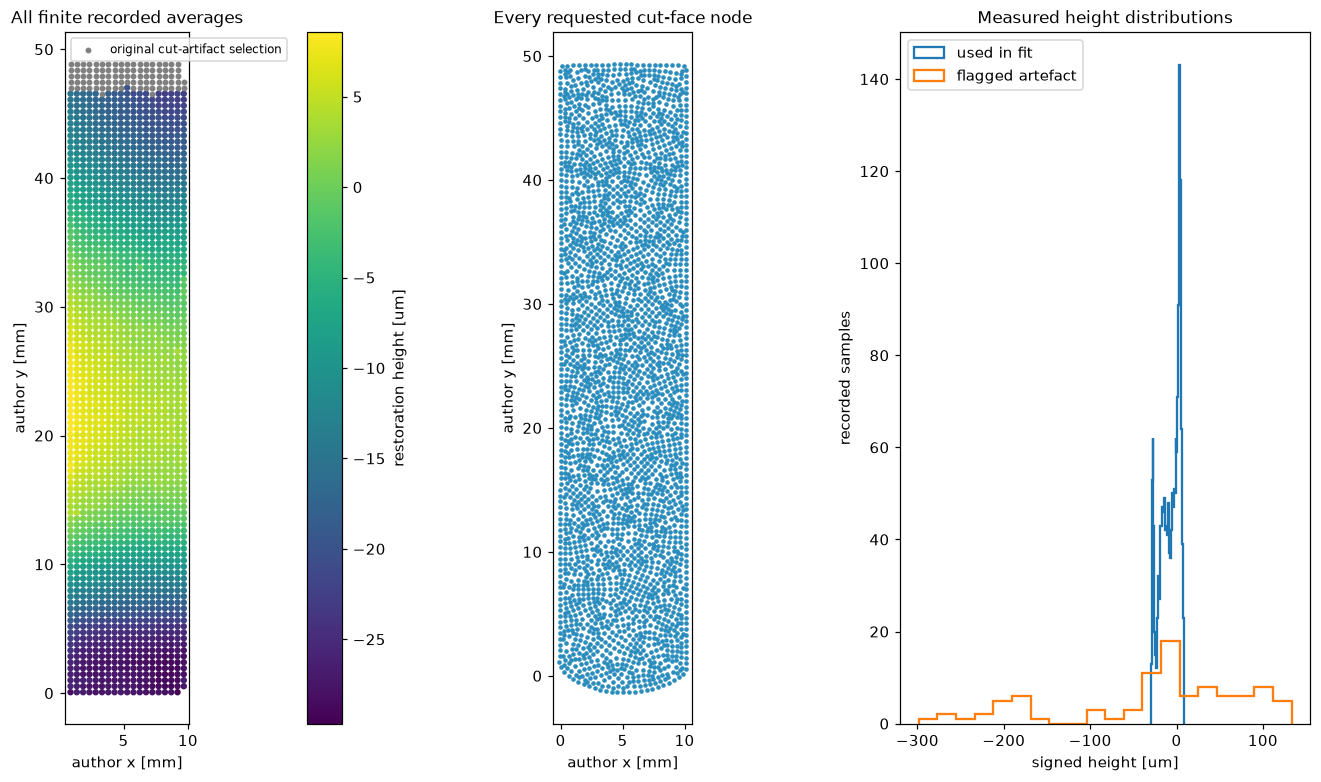

In [2]:
raw=load_raw(T/'data/raw_data.npz')
p=raw['surface_samples'];mask=raw['fit_mask'];ids=raw['surface_node_indices']
xy=raw['mesh_nodes'][ids,:2]-1
fig,ax=plt.subplots(1,3,figsize=(14,7),layout='constrained')
v=ax[0].scatter(p[mask,0],p[mask,1],c=p[mask,2]*1000,s=10,cmap='viridis')
ax[0].scatter(p[~mask,0],p[~mask,1],c='gray',s=8,label='original cut-artifact selection')
ax[0].legend(loc='upper left',fontsize=8);ax[0].set_title('All finite recorded averages');ax[0].set_aspect('equal');ax[0].set_xlabel('author x [mm]');ax[0].set_ylabel('author y [mm]');fig.colorbar(v,ax=ax[0],label='restoration height [um]')
ax[1].scatter(xy[:,0],xy[:,1],s=4,color='#2b8cbe');ax[1].set_title('Every requested cut-face node');ax[1].set_aspect('equal');ax[1].set_xlabel('author x [mm]');ax[1].set_ylabel('author y [mm]')
ax[2].hist(p[mask,2]*1000,bins=40,label='used in fit',histtype='step',linewidth=1.5);ax[2].hist(p[~mask,2]*1000,bins=20,label='flagged artefact',histtype='step',linewidth=1.5);ax[2].set_xlabel('signed height [um]');ax[2].set_ylabel('recorded samples');ax[2].legend();ax[2].set_title('Measured height distributions')
finish(fig,'figure01_observations',{'samples':p,'fit_mask':mask,'surface_xy':xy},'Real supplied averaged measurements, original input-only quality flags and the complete3166-node output support.')


# 3. Physics: elastic compliance and its inverse

Let displacement be u, strain be epsilon and stress be sigma. Equilibrium is divergence(sigma)=0. Isotropic elasticity gives sigma=lambda tr(epsilon)I+2mu epsilon, with epsilon the symmetric displacement gradient, lambda and mu the Lame moduli, and I the identity. Young's modulus is195600MPa and Poisson's ratio is0.294. At the cut plane the outward normal is negative z, so a positive normal stress corresponds to a negative-z traction.

Normal restoration displacement equals the supplied signed height. Tangential cut traction and all other exterior tractions are zero. Three in-plane rigid degrees of freedom are fixed by the input anchors. Inverting the traction-to-contour compliance can therefore be implemented by a contour fit followed by the elastic Dirichlet-to-stress map.

For an eight-node brick, N is the trilinear shape function and the integration-point strain is B times nodal displacement, where B contains physical shape derivatives. The stiffness is the sum of B-transpose D B times the Jacobian determinant over eight Gauss points; D is the isotropic engineering-strain constitutive matrix. Stress is D B u. The known control below is a unit cube with u(z)=0.001xz mm: its normal stress is an independently known linear function of x.

The equations are

$$
\epsilon=\tfrac12(\nabla u+(\nabla u)^T),\qquad
\sigma=\lambda\operatorname{tr}(\epsilon)I+2\mu\epsilon,\qquad
K=\sum_e\sum_g B_g^T D B_g\det J_g.
$$

The indices e and g identify an element and one of its eight integration points; J is the mapping Jacobian from natural to physical coordinates. Element stiffness contributions are assembled at shared degrees of freedom. D uses engineering shear strain and stresses are in MPa.

The original source mistakenly applies a forward shape matrix to Gauss stresses. Independent native controls show72%relative error on this simple linear-stress case. The qualified postprocessor uses the inverse interpolation matrix in actual native quadrature order. Six native controls, including rigid motion and arbitrary trilinear displacement, passed before local extraction. This is a disclosed correction, not unchanged reproduction.


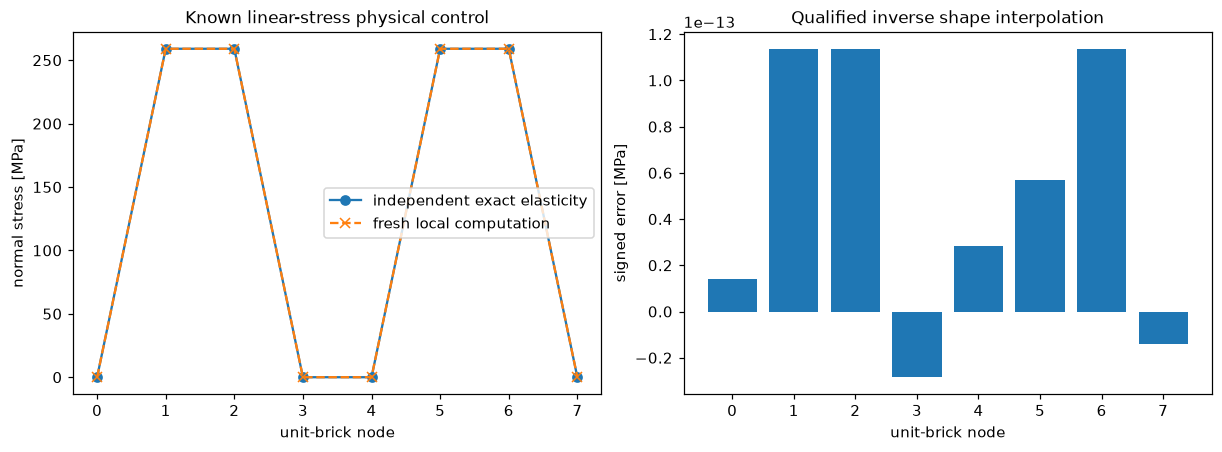

In [3]:
unit_nodes=(NODE_SIGNS+1)/2
unit_cells=np.arange(8)[None]
unit_u=np.column_stack((np.zeros((8,2)),.001*unit_nodes[:,0]*unit_nodes[:,2]))
unit_gp=integration_stress(unit_nodes,unit_cells,unit_u)
unit_sigma=nodal_normal_stress(unit_cells,unit_gp,8)
E=195600.;nu=.294;mu=E/(2*(1+nu));lam=E*nu/((1+nu)*(1-2*nu))
unit_expected=(lam+2*mu)*.001*unit_nodes[:,0]
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
ax[0].plot(np.arange(8),unit_expected,'o-',label='independent exact elasticity');ax[0].plot(np.arange(8),unit_sigma,'x--',label='fresh local computation');ax[0].set_xlabel('unit-brick node');ax[0].set_ylabel('normal stress [MPa]');ax[0].legend();ax[0].set_title('Known linear-stress physical control')
ax[1].bar(np.arange(8),unit_sigma-unit_expected);ax[1].set_xlabel('unit-brick node');ax[1].set_ylabel('signed error [MPa]');ax[1].set_title('Qualified inverse shape interpolation')
finish(fig,'figure02_physical_control',{'expected':unit_expected,'fresh':unit_sigma,'gauss_stress':unit_gp},'Fresh local known-field elasticity and Gauss-to-node inversion, compared with an independent analytic field.')


# 4. Method: active reconstruction from the observations

The profile is a least-squares tensor-product cubic spline over the reliable measurements. Its coefficients minimize the sum of squared height residuals in millimetres; knot counts and endpoint multiplicities preserve the source's nominal3/7mm controls. Actual knots use linspace with the integer interval-count convention, so nominal spacing is not an assertion of exactly3/7mm distance between every knot.

The fitted profile supplies all cut-face displacements, including the unreliable-observation region. Explicit local brick assembly and a general sparse LU solve recover the restoration displacement, followed by constitutive stress, inverse Gauss-to-node interpolation and the source's equal-count nodal averaging. The old second-anchor card leaves a rigid rotational gauge; an independently executed native gauge control showed that imposing the intended additional anchor changes no physical stress beyond native numerical precision. The local solve fixes that gauge explicitly.

For cubic basis functions T and unknown coefficients c, solve

$$
\min_c\sum_{i\in\mathcal V}\left[\sum_{ab}c_{ab}T_a(x_i)T_b(y_i)-h_i\right]^2,
\qquad K_{ff}u_f=-K_{fd}u_d.
$$

The set V contains the original reliable samples, h is observed signed height, f denotes unconstrained displacement degrees of freedom and d denotes prescribed degrees. Fixed displacements u(d) are evaluated from the fitted profile. For the shape-interpolation matrix G from eight nodal values to eight Gauss values, the nodal stress is G-inverse times Gauss stress; adjacent-element contributions are averaged with equal counts.

The call below computes the complete bound reconstruction anew. It never loads a reconstructed field to initialize or replace this computation. All full Gauss-point stress values, reactions and energy are fresh diagnostics from that same solve.


In [4]:
progress('bound full reconstruction started')
started=time.perf_counter()
fresh=reconstruct(raw)
fresh_seconds=time.perf_counter()-started
prediction=T/'output/reconstruction.npz';prediction.parent.mkdir(exist_ok=True)
np.savez_compressed(prediction,reconstruction=fresh['reconstruction'])
spec=importlib.util.spec_from_file_location('independent_contour_judge',T/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(prediction)
(T/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
assert report['passed'],report
print(json.dumps({'fresh_seconds':fresh_seconds,'judge':report,'free_force_relative':fresh['free_dof_force_relative'],'strain_energy_Nmm':fresh['strain_energy_n_mm']},indent=2))
with np.load(T/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as z:upstream={k:z[k] for k in z.files}
with np.load(T/'test/fixtures/native_full_stress.npz',allow_pickle=False) as z:native_gp=z['native_stress']
q=fresh['reconstruction'][0]


{
  "fresh_seconds": 54.192057400010526,
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "ncc": 0.9999999999999745,
      "nrmse": 3.953274091611206e-08,
      "max_abs_mpa": 0.00013524392841191002
    },
    "thresholds": {
      "ncc": {
        "comparison": ">=",
        "boundary": 0.999999
      },
      "nrmse": {
        "comparison": "<=",
        "boundary": 1e-06
      },
      "max_abs_mpa": {
        "comparison": "<=",
        "boundary": 0.001
      }
    },
    "errors": []
  },
  "free_force_relative": 1.3587417786867726e-12,
  "strain_energy_Nmm": 311.6602091086736
}


# 5. Results: complete fields, source comparisons and sensitivity

The reproduced native original and qualified results below use these exact observations. They are method measurements, not physical ground truth. Every field metric evaluates all3,166nodes with no alignment or output scaling. Display coordinates use the known author frame. The source-output rounding envelope fixed the numerical acceptance limits before any local extraction.


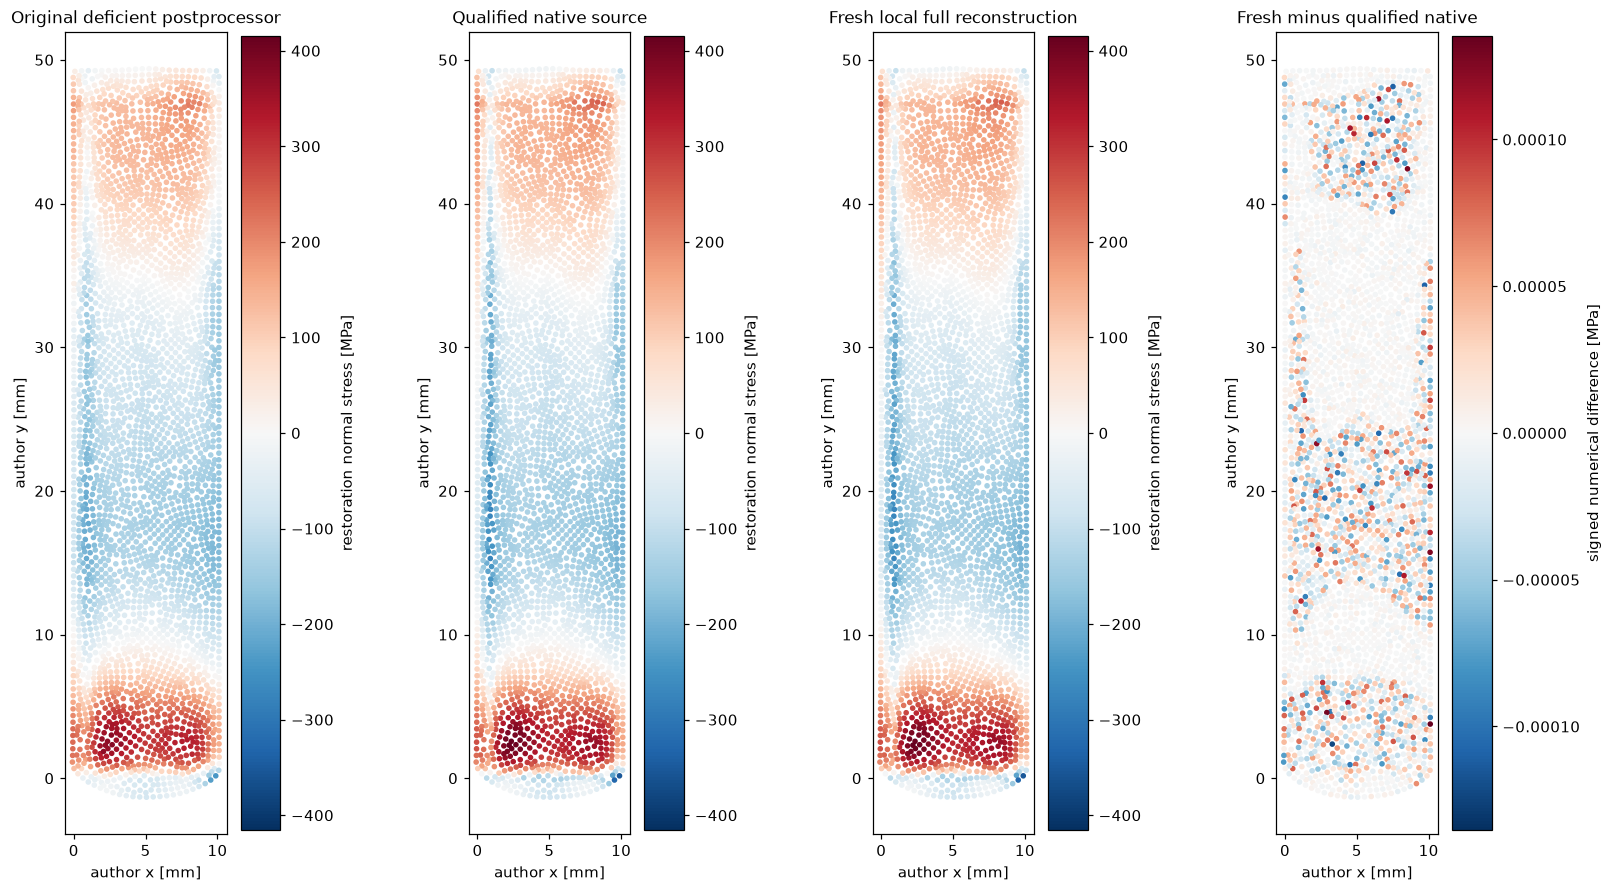

In [5]:
fig,ax=plt.subplots(1,4,figsize=(15,8),layout='constrained')
shared=max(abs(q).max(),abs(upstream['qualified']).max(),abs(upstream['original_deficient']).max())
for a,v,title in zip(ax[:3],[upstream['original_deficient'],upstream['qualified'],q],['Original deficient postprocessor','Qualified native source','Fresh local full reconstruction']):
    im=stress_panel(a,xy,v,title,shared);fig.colorbar(im,ax=a,label='restoration normal stress [MPa]')
im=stress_panel(ax[3],xy,q-upstream['qualified'],'Fresh minus qualified native');fig.colorbar(im,ax=ax[3],label='signed numerical difference [MPa]')
finish(fig,'figure03_full_stress_maps',{'xy':xy,'original_deficient':upstream['original_deficient'],'qualified_native':upstream['qualified'],'fresh':q},'All3166nodes, common signed physical scale for original/native/fresh stress; the difference uses its separately labeled numerical scale.')


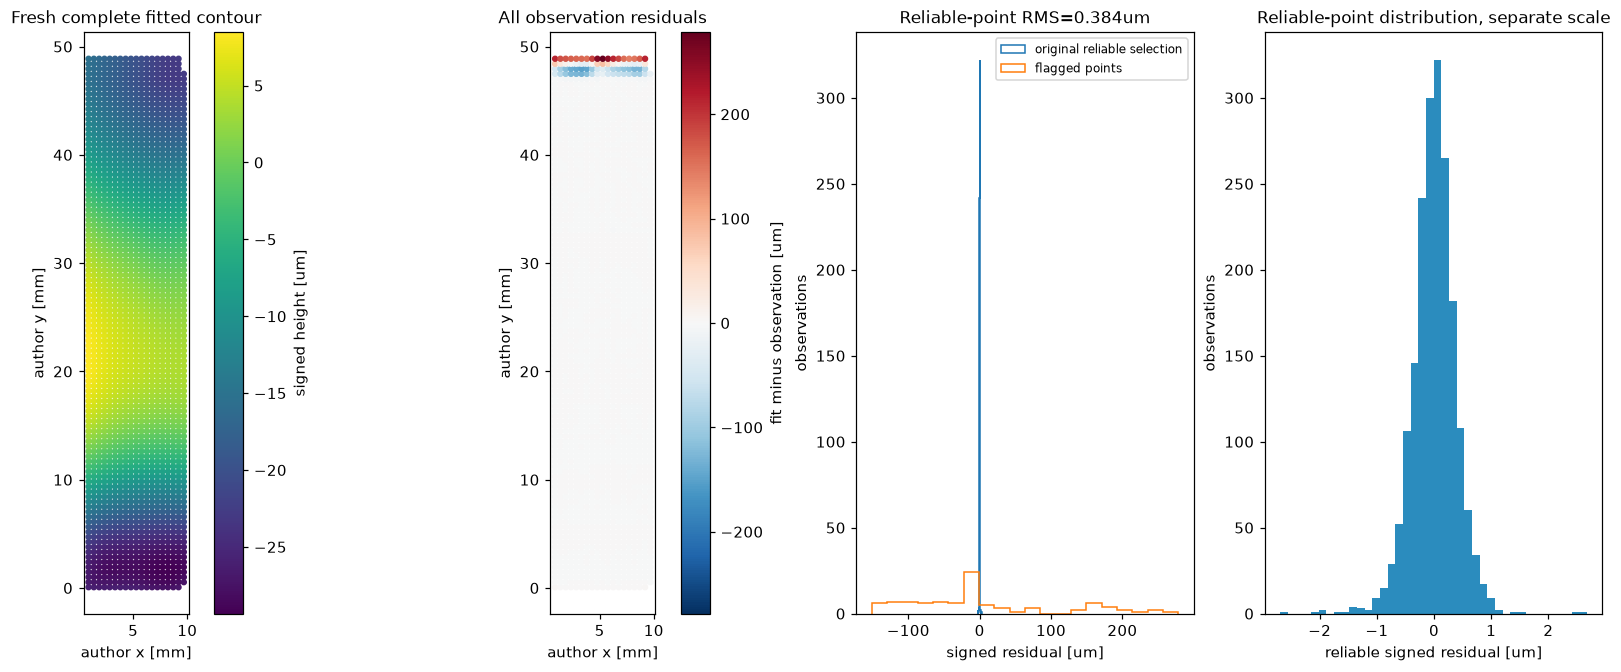

In [6]:
fitted=np.array([bisplev(x,y,fresh['spline']) for x,y in p[:,:2]])
residual=(fitted-p[:,2])*1000
height_rmse=float(np.sqrt(np.mean(residual[mask]**2)))
fig,ax=plt.subplots(1,4,figsize=(16,6),layout='constrained')
v=ax[0].scatter(p[:,0],p[:,1],c=fitted*1000,s=10,cmap='viridis');ax[0].set_aspect('equal');ax[0].set_title('Fresh complete fitted contour');fig.colorbar(v,ax=ax[0],label='signed height [um]')
limit=abs(residual).max();v=ax[1].scatter(p[:,0],p[:,1],c=residual,s=10,cmap='RdBu_r',vmin=-limit,vmax=limit);ax[1].set_aspect('equal');ax[1].set_title('All observation residuals');fig.colorbar(v,ax=ax[1],label='fit minus observation [um]')
for a in ax[:2]:a.set_xlabel('author x [mm]');a.set_ylabel('author y [mm]')
ax[2].hist(residual[mask],bins=40,histtype='step',label='original reliable selection');ax[2].hist(residual[~mask],bins=20,histtype='step',label='flagged points');ax[2].set_xlabel('signed residual [um]');ax[2].set_ylabel('observations');ax[2].legend(fontsize=8);ax[2].set_title(f'Reliable-point RMS={height_rmse:.3f}um')
ax[3].hist(residual[mask],bins=40,color='#2b8cbe');ax[3].set_xlabel('reliable signed residual [um]');ax[3].set_ylabel('observations');ax[3].set_title('Reliable-point distribution, separate scale')
finish(fig,'figure04_contour_consistency',{'samples':p,'fit_mask':mask,'fitted_height_mm':fitted,'residual_um':residual},'Fresh contour fit and signed residuals at every observed location; the original input-only quality selection remains explicit.')


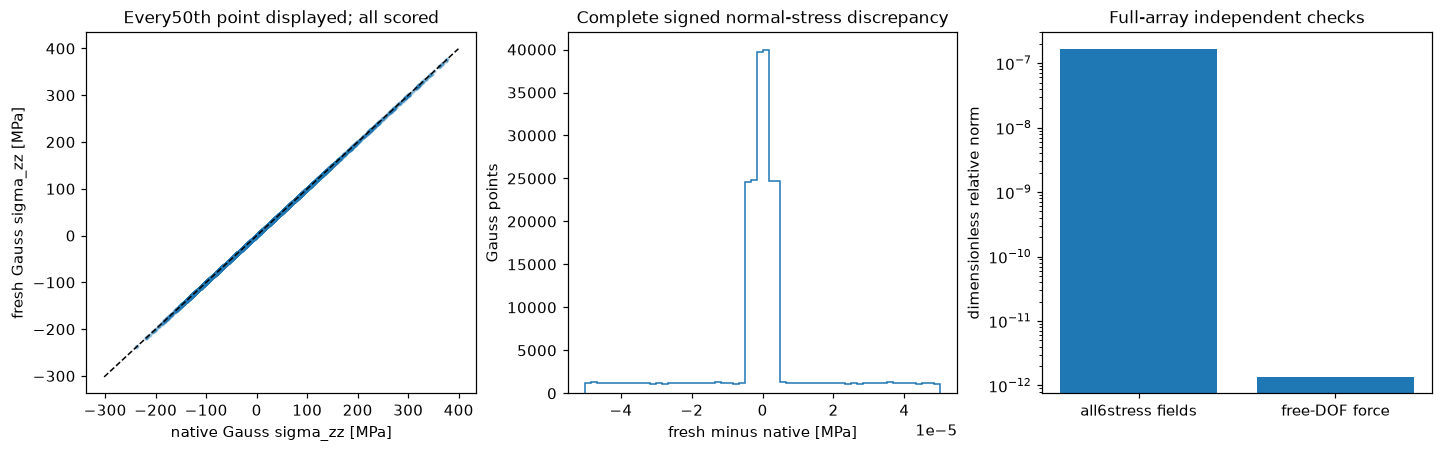

In [7]:
gauss_relative=float(np.linalg.norm(fresh['gauss_stress']-native_gp)/np.linalg.norm(native_gp))
a=native_gp[:,:,2].ravel();b=fresh['gauss_stress'][:,:,2].ravel()
fig,ax=plt.subplots(1,3,figsize=(13,4),layout='constrained')
ax[0].scatter(a[::50],b[::50],s=3,alpha=.3);lim=[min(a.min(),b.min()),max(a.max(),b.max())];ax[0].plot(lim,lim,'k--',lw=1);ax[0].set_xlabel('native Gauss sigma_zz [MPa]');ax[0].set_ylabel('fresh Gauss sigma_zz [MPa]');ax[0].set_title('Every50th point displayed; all scored')
ax[1].hist((b-a),bins=60,histtype='step');ax[1].set_xlabel('fresh minus native [MPa]');ax[1].set_ylabel('Gauss points');ax[1].set_title('Complete signed normal-stress discrepancy')
ax[2].bar(['all6stress fields','free-DOF force'],[gauss_relative,fresh['free_dof_force_relative']]);ax[2].set_yscale('log');ax[2].set_ylabel('dimensionless relative norm');ax[2].set_title('Full-array independent checks')
finish(fig,'figure05_native_stage_comparison',{'native_gauss_stress':native_gp,'fresh_gauss_stress':fresh['gauss_stress'],'relative_errors':np.array([gauss_relative,fresh['free_dof_force_relative']])},'Fresh all1,457,760stress values compared with actual complete native execution; scatter sampling affects display only.')


Actually computed full-domain sensitivity runtimes: {'3/6': 53.51303820000612, '3/8': 57.679644199990435, 'all_points3/7': 57.25890759998583}


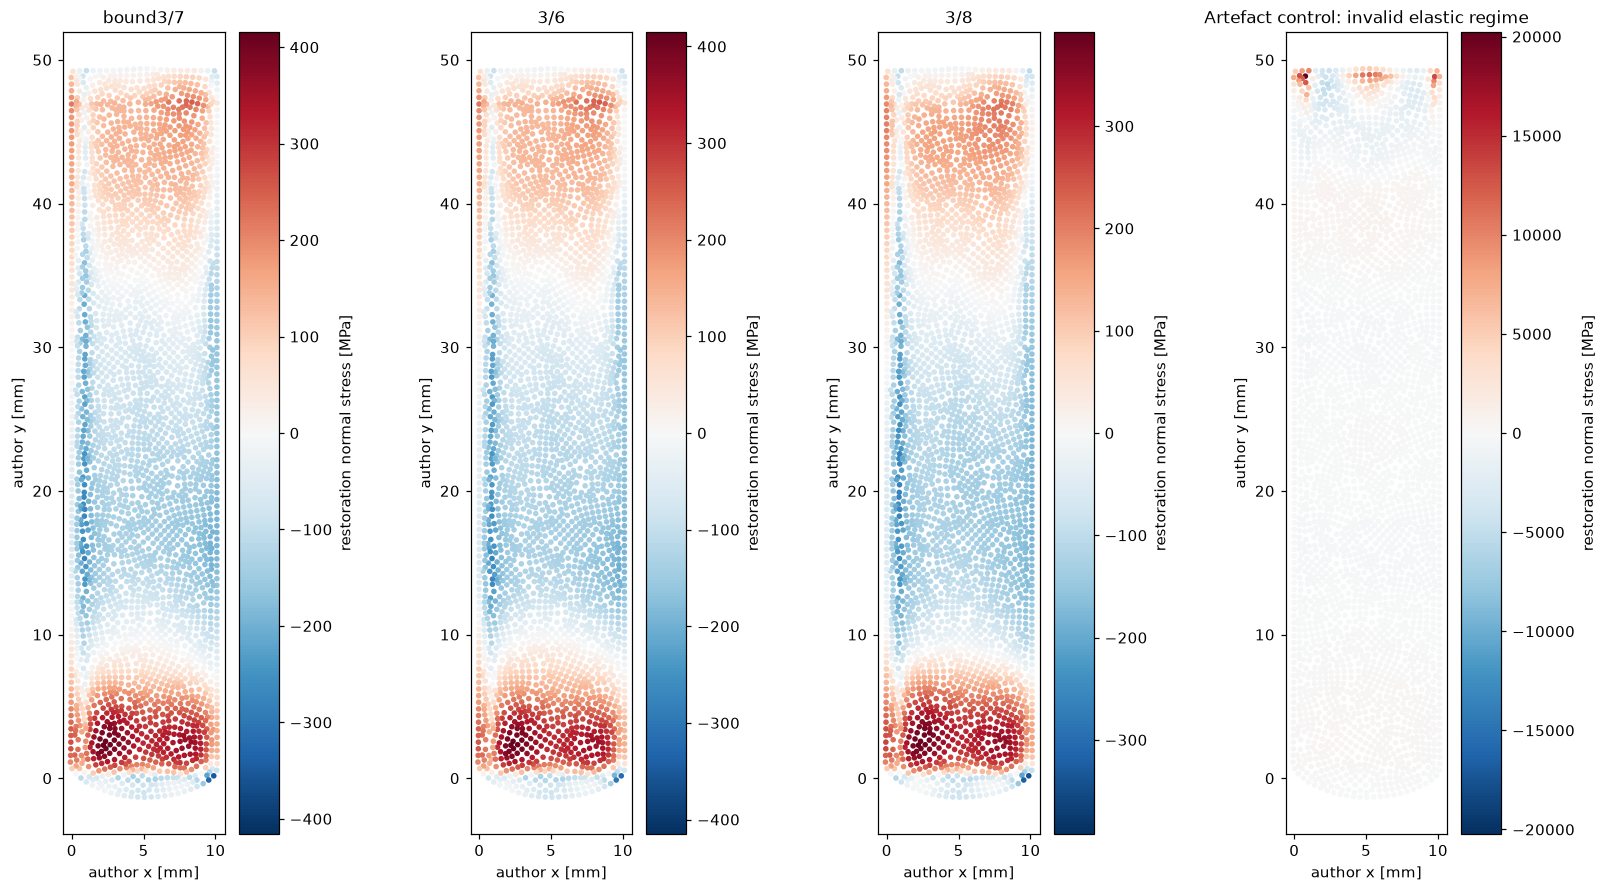

In [8]:
comparisons={'bound3/7':fresh};variant_seconds={}
for name,spacing,use_mask in [('3/6',(3.,6.),True),('3/8',(3.,8.),True),('all_points3/7',(3.,7.),False)]:
    progress('full variant '+name+' started')
    altered={k:v.copy() for k,v in raw.items()}
    if not use_mask:altered['fit_mask'][:]=True
    started=time.perf_counter();comparisons[name]=reconstruct(altered,knot_spacing=spacing);variant_seconds[name]=time.perf_counter()-started
print('Actually computed full-domain sensitivity runtimes:',variant_seconds)
fig,ax=plt.subplots(1,4,figsize=(15,8),layout='constrained')
for a,(name,result) in zip(ax,comparisons.items()):
    field=result['reconstruction'][0];title=name if name!='all_points3/7' else 'Artefact control: invalid elastic regime';im=stress_panel(a,xy,field,title);fig.colorbar(im,ax=a,label='restoration normal stress [MPa]')
finish(fig,'figure06_actual_sensitivity_maps',{'xy':xy,**{name.replace('/','_'):r['reconstruction'] for name,r in comparisons.items()}},'Four actually solved full elastic inverses: fixed benchmark, two nominal knot choices and all measured points including the known artefact; each panel labels its own physical color scale. The unmasked artefact control reaches physically inadmissible stresses and is not an acceptable elastic recovery.')


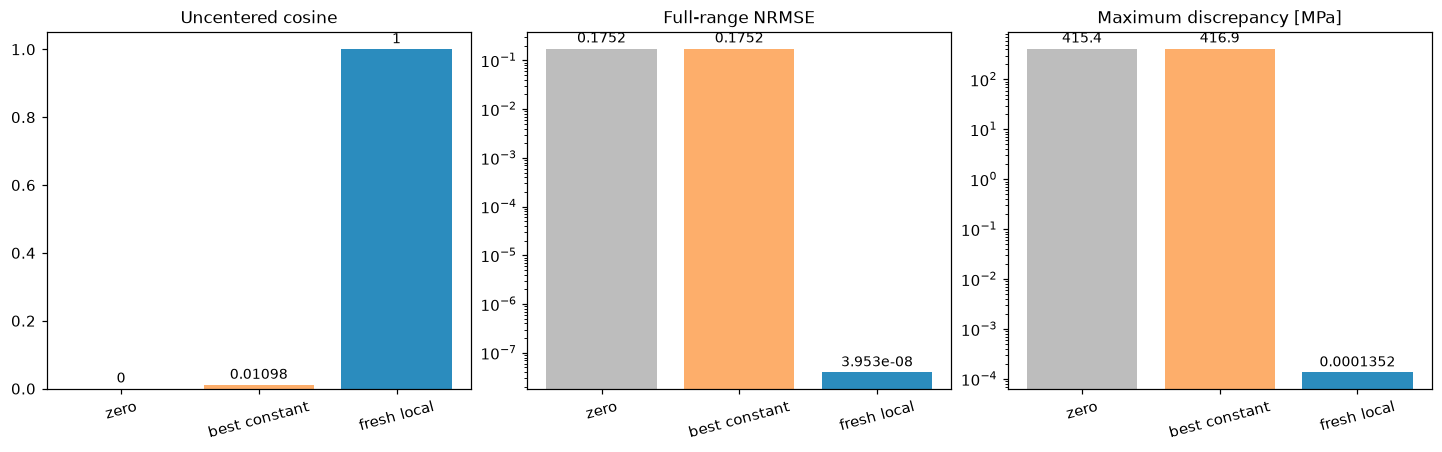

In [9]:
labels=['zero','best constant','fresh local']
estimates=[np.zeros_like(q),np.full_like(q,upstream['qualified'].mean()),q]
metrics=[comparison_metrics(x,upstream['qualified']) for x in estimates]
fig,ax=plt.subplots(1,3,figsize=(13,4),layout='constrained')
for a,key,title in zip(ax,['ncc','nrmse','max_abs_mpa'],['Uncentered cosine','Full-range NRMSE','Maximum discrepancy [MPa]']):
    values=[m[key] for m in metrics];a.bar(labels,values,color=['#bdbdbd','#fdae6b','#2b8cbe']);a.set_title(title);a.tick_params(axis='x',rotation=15)
    if key!='ncc':a.set_yscale('log')
    for i,v in enumerate(values):a.annotate(f'{v:.4g}',(i,v),xytext=(0,4),textcoords='offset points',ha='center',fontsize=9)
finish(fig,'figure07_metrics_and_nulls',{'ncc':np.array([m['ncc'] for m in metrics]),'nrmse':np.array([m['nrmse'] for m in metrics]),'max_abs_mpa':np.array([m['max_abs_mpa'] for m in metrics])},'Full3166node metrics against the qualified standard method, including deliberately poor matched-shape nulls; reference agreement is not spatial truth.')


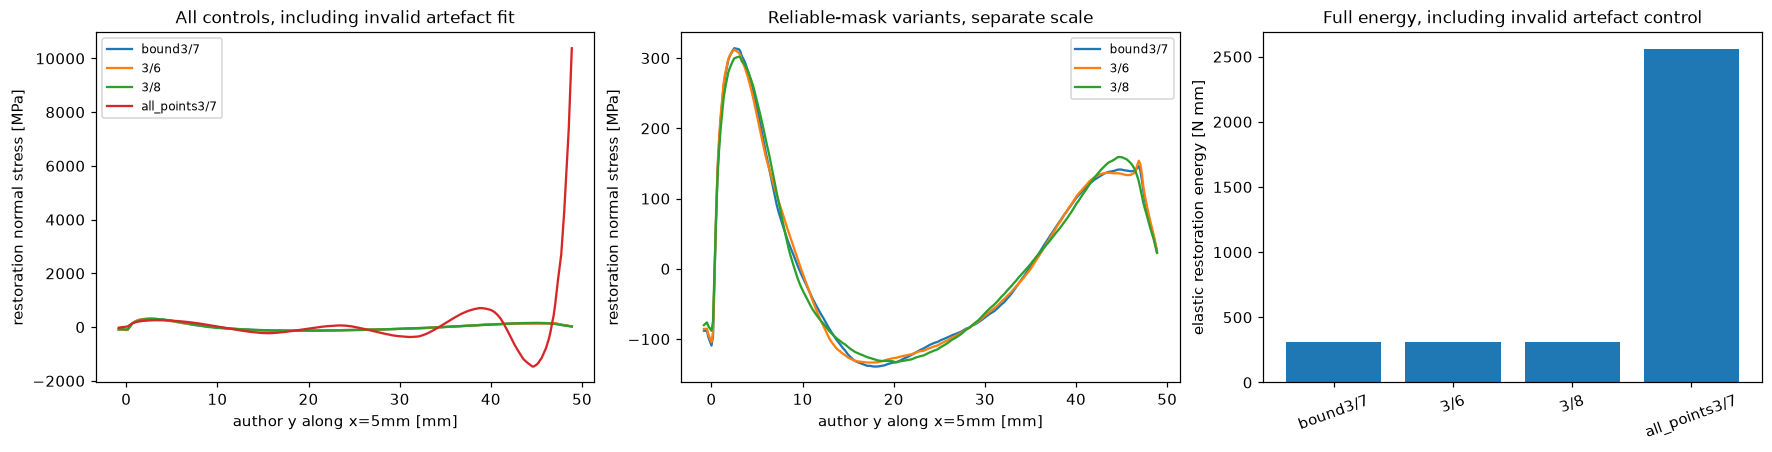

{
  "ncc": 0.9999999999999749,
  "nrmse": 3.953274091611206e-08,
  "max_abs_mpa": 0.00013524392841191002,
  "fresh_seconds": 54.192057400010526,
  "height_rmse_um": 0.3844199477156876,
  "gauss_relative": 1.6718661775644972e-07,
  "strain_energy_n_mm": 311.6602091086736
}
Actual figure groups: 8


In [10]:
line_y=np.linspace(xy[:,1].min()+.5,xy[:,1].max()-.5,300)
query=np.column_stack((np.full(300,5.),line_y))
profiles={name:LinearNDInterpolator(xy,r['reconstruction'][0])(query) for name,r in comparisons.items()}
fig,ax=plt.subplots(1,3,figsize=(16,4),layout='constrained')
for name,profile in profiles.items():ax[0].plot(line_y,profile,label=name)
for name,profile in profiles.items():
    if name!='all_points3/7':ax[1].plot(line_y,profile,label=name)
ax[1].set_xlabel('author y along x=5mm [mm]');ax[1].set_ylabel('restoration normal stress [MPa]');ax[1].legend(fontsize=8);ax[1].set_title('Reliable-mask variants, separate scale')
ax[0].set_xlabel('author y along x=5mm [mm]');ax[0].set_ylabel('restoration normal stress [MPa]');ax[0].legend(fontsize=8);ax[0].set_title('All controls, including invalid artefact fit')
names=list(comparisons);ax[2].bar(names,[r['strain_energy_n_mm'] for r in comparisons.values()]);ax[2].set_ylabel('elastic restoration energy [N mm]');ax[2].tick_params(axis='x',rotation=20);ax[2].set_title('Full energy, including invalid artefact control')
finish(fig,'figure08_profiles_and_energy',{'line_y_mm':line_y,**{name.replace('/','_'):a for name,a in profiles.items()},'energy_n_mm':np.array([r['strain_energy_n_mm'] for r in comparisons.values()])},'All four freshly solved stress fields sampled along the same known-geometry midline, with full-body elastic restoration energy; this is not a reference-dependent alignment.')
measured=dict(**comparison_metrics(q,upstream['qualified']),fresh_seconds=fresh_seconds,height_rmse_um=height_rmse,gauss_relative=gauss_relative,strain_energy_n_mm=fresh['strain_energy_n_mm'])
np.savez_compressed(T/'notebooks/reference_outputs/fresh_cleaned_measurements.npz',**{k:np.array([v]) for k,v in measured.items()})
(EXPORT/'figure_index.json').write_text(json.dumps({'summary':measured,'figures':figures},indent=2,allow_nan=False),encoding='utf8')
print(json.dumps(measured,indent=2));print('Actual figure groups:',len(figures))


# 6. Conclusion and limits

The active notebook reconstructed all3,166 cut-face normal stresses and passed the fixed independent evaluator. All whole-field source comparisons, contour residuals, physical controls and four complete sensitivity reconstructions are actual computations. The all-points control intentionally ignores the original cut-completion artefact flags. Its enormous stress and elastic energy violate the physical linear-elastic regime; it is a failed control, not a valid alternative reconstruction. The valid-mask profiles are also displayed on a separate readable scale, while the complete failed-control values remain visible. The corrected Gauss-to-node map is independently justified; the deficient historical source postprocessor remains an explicit scientific comparison.

No independent spatial stress truth is available. The cut-completion selection, spline basis, assumed uniform elasticity, finite body geometry, boundary rounding and author's restoration sign condition the estimate. The region with unreliable surface measurements remains in the complete reconstructed field and its extrapolation should not be mistaken for equally reliable measured detail. Independent pre-registration CMM release-axis calibration is unavailable. Neither source agreement nor small elastic residual proves original pre-cut stress accuracy or a recovered full interior residual tensor. Data redistribution permission for the processed author record remains separate from the software license.
